# Data Preprocessing: Market Basket Retail Dataset
Notebook ini memuat tahap pra-pemrosesan data (*Data Understanding & Preprocessing*) untuk dataset transaksi ritel keranjang belanja (*Market Basket Analysis*).

* **Dataset:** `Dataset_Transaksi_Retail.csv`
* **Karakteristik Data:** 5.050 baris item transaksi ritel, 1.500 transaksi unik, dan 22 ragam produk dari 4 kategori.
* **Fokus Analisis:**
  1. Pemeriksaan Dimensi Data (Jumlah Record & Atribut)
  2. Analisis Nilai Kosong (*Missing Value*) & Visualisasi Heatmap
  3. Evaluasi Data Duplikat & Integritas Identifier Transaksi
  4. Deteksi Data Pencilan (*Outlier*) pada Ukuran Keranjang Belanja menggunakan Metode IQR dan Boxplot

### 1. Import Library
Memanggil library data science (pandas, numpy, matplotlib, seaborn).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Membaca Dataset
Memuat file CSV dataset transaksi ritel ke dalam DataFrame pandas.

In [2]:
df = pd.read_csv('Dataset_Transaksi_Retail.csv')

### 3. Menampilkan 5 Data Teratas (Head)
Melihat sampel 5 baris pertama data transaksi.

In [3]:
df.head()

,Transaction_ID,Transaction_Date,Product,Category,Quantity
0,TRX1411,2025-03-30,Eggs,Breakfast,1.0
1,TRX0208,2025-06-24,Eggs,Breakfast,1.0
2,TRX0019,2025-03-26,Chips,Snacks,1.0
3,TRX1031,2025-04-19,Tissue,Personal Care,1.0
4,TRX1447,2025-02-14,Soap,Personal Care,2.0


### 4. Menampilkan 5 Data Terbawah (Tail)
Melihat sampel 5 baris terakhir data transaksi.

In [4]:
df.tail()

,Transaction_ID,Transaction_Date,Product,Category,Quantity
5045,TRX1327,2025-03-22,Cheese,Breakfast,2.0
5046,TRX0141,2025-05-16,Shampoo,Personal Care,1.0
5047,TRX0932,2025-04-13,Tomato Sauce,Cooking,2.0
5048,TRX1138,2025-02-07,Shampoo,Personal Care,1.0
5049,TRX0260,2025-02-20,Cheese,Breakfast,2.0


### 5. Jumlah Baris (Record)
Menghitung total baris record transaksi dalam dataset.

In [5]:
print("Jumlah Baris:", df.shape[0])

Jumlah Baris: 5050


### 6. Jumlah Kolom (Atribut)
Menghitung total atribut kolom data.

In [6]:
print("Jumlah Kolom:", df.shape[1])

Jumlah Kolom: 5


### 7. Cek Tipe Data & Struktur Kolom
Memeriksa tipe data masing-masing kolom dan penggunaan memori.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    5050 non-null   str    
 1   Transaction_Date  5050 non-null   str    
 2   Product           5050 non-null   str    
 3   Category          5025 non-null   str    
 4   Quantity          5025 non-null   float64
dtypes: float64(1), str(4)
memory usage: 197.4 KB


### 8. Cek Missing Value per Kolom
Mendeteksi jumlah nilai kosong (null/NaN) pada setiap kolom atribut.

In [8]:
df.isna().sum()

Transaction_ID       0
Transaction_Date     0
Product              0
Category            25
Quantity            25
dtype: int64

### 9. Total Missing Value Keseluruhan
Menghitung akumulasi seluruh nilai kosong di seluruh tabel.

In [9]:
print("Total Missing Value:", df.isna().sum().sum())

Total Missing Value: 50


### 10. Persentase Missing Value (%)
Menghitung persentase rasio nilai kosong terhadap total baris data.

In [10]:
(df.isna().sum() / len(df) * 100).round(2)

Transaction_ID      0.0
Transaction_Date    0.0
Product             0.0
Category            0.5
Quantity            0.5
dtype: float64

### 11. Visualisasi Heatmap Missing Value
Menampilkan sebaran visual nilai kosong pada dataset transaksi.

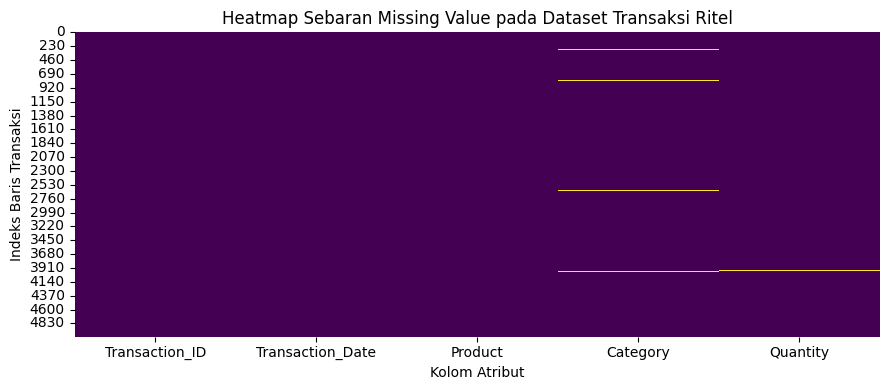

In [11]:
plt.figure(figsize=(9, 4))
sns.heatmap(df.isna(), cbar=False, cmap='viridis')
plt.title('Heatmap Sebaran Missing Value pada Dataset Transaksi Ritel')
plt.xlabel('Kolom Atribut')
plt.ylabel('Indeks Baris Transaksi')
plt.tight_layout()
plt.show()

### 12. Cek Jumlah Duplikat Penuh
Menghitung baris transaksi yang identik di semua kolom atribut.

In [12]:
print("Jumlah Duplikat Penuh:", df.duplicated().sum())

Jumlah Duplikat Penuh: 40


### 13. Cek Jumlah Transaksi Unik (Identifier)
Menghitung banyaknya struk / nomor transaksi unik (Transaction_ID).

In [13]:
print("Jumlah Transaksi Unik:", df["Transaction_ID"].nunique())

Jumlah Transaksi Unik: 1500


### 14. Ringkasan Kategori dan Jumlah Produk
Menampilkan variasi kategori dan jumlah produk unik dalam dataset.

In [14]:
print("Jumlah Kategori Produk:", df["Category"].nunique())
print("Jumlah Produk Unik:", df["Product"].nunique())

Jumlah Kategori Produk: 4
Jumlah Produk Unik: 22


### 15. Hitung Ukuran Keranjang Belanja per Transaksi
Menghitung berapa banyak item produk yang dibeli dalam setiap nomor struk (Transaction_ID).

In [15]:
item_per_transaksi = df.groupby('Transaction_ID')['Product'].count()

### 16. Statistik Deskriptif Ukuran Keranjang Belanja
Menganalisis nilai rata-rata, standar deviasi, nilai minimum, median, dan maksimum keranjang.

In [16]:
item_per_transaksi.describe()

count    1500.000000
mean        3.366667
std         0.869900
min         2.000000
25%         3.000000
50%         3.000000
75%         4.000000
max         6.000000
Name: Product, dtype: float64

### 17. Visualisasi Boxplot Ukuran Keranjang Belanja
Menampilkan distribusi ukuran belanja dan titik-titik anomali (outlier).

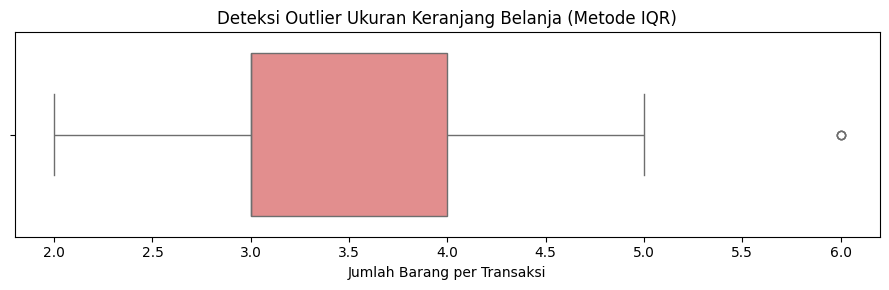

In [17]:
plt.figure(figsize=(9, 3))
sns.boxplot(x=item_per_transaksi, color='lightcoral')
plt.title('Deteksi Outlier Ukuran Keranjang Belanja (Metode IQR)')
plt.xlabel('Jumlah Barang per Transaksi')
plt.tight_layout()
plt.show()

### 18. Perhitungan Kuartil (Q1, Q3) dan Interquartile Range (IQR)
Menghitung kuartil bawah (Q1), kuartil atas (Q3), dan selisih rentang antarkuartil (IQR).

In [18]:
Q1 = item_per_transaksi.quantile(0.25)
Q3 = item_per_transaksi.quantile(0.75)
IQR = Q3 - Q1
print("Q1 (Kuartil 1):", Q1)
print("Q3 (Kuartil 3):", Q3)
print("IQR (Rentang Antarkuartil):", IQR)

Q1 (Kuartil 1): 3.0
Q3 (Kuartil 3): 4.0
IQR (Rentang Antarkuartil): 1.0


### 19. Perhitungan Batas Atas Outlier (Tukey Rule)
Menentukan batas ambang batas atas untuk mengklasifikasikan transaksi outlier.

In [19]:
batas_atas = Q3 + 1.5 * IQR
print("Batas Atas Outlier:", batas_atas)

Batas Atas Outlier: 5.5


### 20. Jumlah Transaksi Terdeteksi Outlier
Menghitung total transaksi yang melampaui batas atas IQR.

In [20]:
outliers = item_per_transaksi[item_per_transaksi > batas_atas]
print("Jumlah Transaksi Outlier:", len(outliers))

Jumlah Transaksi Outlier: 3


### 21. Daftar Transaksi Outlier Terbesar
Menampilkan transaksi belanja dengan jumlah item produk tertinggi.

In [21]:
outliers.sort_values(ascending=False).head(10)

Transaction_ID
TRX0147    6
TRX0533    6
TRX0561    6
Name: Product, dtype: int64